# HealthTrust Watch — Phase II: Exploratory NLP Analysis

**Course:** INFO 4360 — NLP for Real-World Problems  
**Application:** MyChart  
**Dataset:** Health App Reviews for Privacy & Trust (HARPT)  
**Analysis Path:** Path B — Understanding and Extraction

## 1. Data Loading and Initial Exploration

This notebook investigates user-reported concerns in MyChart healthcare application reviews. We begin by extracting MyChart reviews from HARPT and examining the dataset's structure before cleaning or text mining.

The analysis is descriptive rather than predictive. Existing trust-related annotations are not assumed to represent verified complaints.

In [1]:
import pandas as pd
from pathlib import Path

# Locate the HARPT dataset regardless of Jupyter's working directory
possible_paths = [
    Path("data/HARPT.csv"),
    Path("../data/HARPT.csv"),
    Path("HealthTrust-Watch/data/HARPT.csv"),
]

data_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "HARPT.csv not found. Make sure the file is inside "
        "HealthTrust-Watch/data/"
    )

print("Loading dataset from:", data_path.resolve())

# Load the original HARPT dataset
df = pd.read_csv(data_path, low_memory=False)

# Inspect the complete dataset
print("\nTotal HARPT reviews:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

# Extract MyChart reviews only
mychart_df = df.loc[
    df["app_name"].astype(str).str.strip().eq("MyChart")
].copy()

print("\nMyChart reviews:", len(mychart_df))

display(mychart_df.head())

C:\Users\sahit\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Loading dataset from: C:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\HARPT.csv

Total HARPT reviews: 480450
Number of columns: 16

Column names:
['reviewId', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'app_name', 'app_id', 'word_count', 'year', 'sentiment', 'App_Type', 'trust_dimension', 'confidence_score']

MyChart reviews: 93392


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,app_name,app_id,word_count,year,sentiment,App_Type,trust_dimension,confidence_score
480,90d8b83b-2298-4bf6-bc3e-f624960ef387,very easy to use and follow up with my care,4,0,10.8.2,4/11/25 19:54,NaN,NaN,MyChart,epic.mychart.android,10,2025,NaN,Patient Portal,data control,0.443538
481,ee61cbec-58f5-4e6a-ab67-d3e1bb8415e7,"Best information, since the wheel.",5,0,11.3.2,4/11/25 19:39,NaN,NaN,MyChart,epic.mychart.android,5,2025,NaN,Patient Portal,data quality,0.982839
482,2617f3cf-1cda-40c9-83c7-412c788f02cb,i found everything i was looking for plus some...,5,0,11.3.1,4/11/25 19:39,NaN,NaN,MyChart,epic.mychart.android,13,2025,NaN,Patient Portal,reliability,0.512631
483,9c1abef6-d1f2-4842-8d5f-4145d5b13a54,MyChart is an incredibly convenient app for ma...,5,0,NaN,4/11/25 19:31,NaN,NaN,MyChart,epic.mychart.android,51,2025,NaN,Patient Portal,data control,0.973237
484,5e606ce4-a11d-4cef-a506-135c95c26862,"it's very helpful, all involved are able to ac...",5,0,11.3.2,4/11/25 19:23,NaN,NaN,MyChart,epic.mychart.android,16,2025,NaN,Patient Portal,data control,0.989216


## 2. Data Quality Assessment

Before performing NLP analysis, we evaluate the completeness and consistency of the extracted MyChart reviews.

This assessment examines missing values, duplicate records, review-text quality, and the availability of important metadata.

These checks help determine which observations are suitable for subsequent text mining and which limitations must be considered when interpreting results.

In [2]:
# Data quality assessment for MyChart reviews

print("Dataset shape:", mychart_df.shape)

# Missing values
missing_summary = pd.DataFrame({
    "Missing Count": mychart_df.isna().sum(),
    "Missing Percentage": (
        mychart_df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

# Duplicate review IDs
duplicate_ids = mychart_df["reviewId"].duplicated().sum()

# Duplicate review text
duplicate_text = mychart_df["content"].duplicated().sum()

print("\nDuplicate review IDs:", duplicate_ids)
print("Duplicate review texts:", duplicate_text)

# Empty or whitespace-only reviews
empty_reviews = (
    mychart_df["content"].fillna("").astype(str).str.strip() == ""
).sum()

print("Empty review texts:", empty_reviews)

# Data types
print("\nColumn data types:")
display(mychart_df.dtypes.to_frame("Data Type"))

Dataset shape: (93392, 16)


,Missing Count,Missing Percentage
reviewId,0,0.00
content,46,0.05
score,0,0.00
thumbsUpCount,0,0.00
reviewCreatedVersion,8050,8.62
at,0,0.00
replyContent,9832,10.53
repliedAt,9832,10.53
app_name,0,0.00
app_id,0,0.00



Duplicate review IDs: 0
Duplicate review texts: 12699
Empty review texts: 46

Column data types:


,Data Type
reviewId,str
content,str
score,int64
thumbsUpCount,int64
reviewCreatedVersion,str
at,str
replyContent,str
repliedAt,str
app_name,str
app_id,str


### Data Quality Findings

The extracted MyChart dataset contains 93,392 reviews.

The initial missing-value assessment shows that:

- Only 46 reviews (0.05%) have missing review text.
- Star ratings and review dates have no missing values.
- Application-version information is missing for 8,050 reviews (8.62%).
- Developer reply information is missing for 9,832 reviews (10.53%).
- The existing sentiment column is entirely empty and will not be used as an analytical input.

These results indicate that the dataset has sufficient text and rating information for exploratory NLP analysis.

Reviews without usable text will be excluded from text analysis. Missing application-version information will be retained as a limitation rather than used as a reason to discard otherwise valid reviews.

The existing trust-dimension labels will not be treated as verified evidence of user complaints.

In [3]:
# Create a working copy without modifying the original dataset
mychart_clean = mychart_df.copy()

# Remove missing or whitespace-only review text
mychart_clean = mychart_clean.dropna(subset=["content"])

mychart_clean["content"] = (
    mychart_clean["content"].astype(str).str.strip()
)

mychart_clean = mychart_clean[
    mychart_clean["content"].ne("")
].copy()

# Parse review dates
mychart_clean["at"] = pd.to_datetime(
    mychart_clean["at"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

# Convert ratings to numeric values
mychart_clean["score"] = pd.to_numeric(
    mychart_clean["score"],
    errors="coerce"
)

# Exclude records with invalid ratings or dates
mychart_clean = mychart_clean.dropna(subset=["score", "at"])

# Remove duplicate review IDs, retaining the first occurrence
mychart_clean = mychart_clean.drop_duplicates(
    subset=["reviewId"],
    keep="first"
)

# Calculate review length from the cleaned text
mychart_clean["review_length_words"] = (
    mychart_clean["content"].str.split().str.len()
)

mychart_clean["review_length_chars"] = (
    mychart_clean["content"].str.len()
)

print("Original MyChart reviews:", len(mychart_df))
print("Cleaned MyChart reviews:", len(mychart_clean))
print("Reviews excluded:", len(mychart_df) - len(mychart_clean))

print("\nDate range:")
print("Earliest:", mychart_clean["at"].min())
print("Latest:", mychart_clean["at"].max())

display(mychart_clean.head())

Original MyChart reviews: 93392
Cleaned MyChart reviews: 93346
Reviews excluded: 46

Date range:
Earliest: 2011-11-01 14:21:00
Latest: 2025-04-12 01:29:00


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,app_name,app_id,word_count,year,sentiment,App_Type,trust_dimension,confidence_score,review_length_words,review_length_chars
480,90d8b83b-2298-4bf6-bc3e-f624960ef387,very easy to use and follow up with my care,4,0,10.8.2,2025-04-11 19:54:00,NaN,NaN,MyChart,epic.mychart.android,10,2025,NaN,Patient Portal,data control,0.443538,10,43
481,ee61cbec-58f5-4e6a-ab67-d3e1bb8415e7,"Best information, since the wheel.",5,0,11.3.2,2025-04-11 19:39:00,NaN,NaN,MyChart,epic.mychart.android,5,2025,NaN,Patient Portal,data quality,0.982839,5,34
482,2617f3cf-1cda-40c9-83c7-412c788f02cb,i found everything i was looking for plus some...,5,0,11.3.1,2025-04-11 19:39:00,NaN,NaN,MyChart,epic.mychart.android,13,2025,NaN,Patient Portal,reliability,0.512631,13,66
483,9c1abef6-d1f2-4842-8d5f-4145d5b13a54,MyChart is an incredibly convenient app for ma...,5,0,NaN,2025-04-11 19:31:00,NaN,NaN,MyChart,epic.mychart.android,51,2025,NaN,Patient Portal,data control,0.973237,51,332
484,5e606ce4-a11d-4cef-a506-135c95c26862,"it's very helpful, all involved are able to ac...",5,0,11.3.2,2025-04-11 19:23:00,NaN,NaN,MyChart,epic.mychart.android,16,2025,NaN,Patient Portal,data control,0.989216,16,92


### Data Cleaning Results and Interpretation

The original MyChart subset contained **93,392 reviews**. After excluding records with missing or unusable review text and applying data-quality checks, **93,346 reviews (99.95%)** remained, representing a reduction of only 46 records (0.05%).

The cleaned dataset spans **November 1, 2011, to April 12, 2025**, allowing historical review patterns to be explored.

The cleaning process preserves original review ratings and available application-version information. Reviews with missing version metadata remain in the general analysis because they can still contribute to keyword, sentiment, and topic exploration.

Duplicate review IDs are checked separately from repeated review text because identical comments may be submitted by different users. The specific reasons for excluded records will be verified before finalizing the audit.

Overall, the dataset provides a substantial foundation for exploratory NLP analysis. However, findings will describe patterns within the HARPT MyChart sample rather than assume that the sample represents all MyChart users.

In [4]:
# Verify the reasons for excluded reviews

missing_text = mychart_df["content"].isna().sum()

empty_text = (
    mychart_df["content"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
).sum()

duplicate_ids = mychart_df["reviewId"].duplicated().sum()

duplicate_texts = (
    mychart_df["content"]
    .dropna()
    .duplicated()
    .sum()
)

print("Missing review text:", missing_text)
print("Missing or blank review text:", empty_text)
print("Duplicate review IDs:", duplicate_ids)
print("Repeated review texts:", duplicate_texts)
print("Total excluded during cleaning:", len(mychart_df) - len(mychart_clean))

Missing review text: 46
Missing or blank review text: 46
Duplicate review IDs: 0
Repeated review texts: 12654
Total excluded during cleaning: 46


### Final Data Quality Assessment

The original MyChart dataset contained 93,392 reviews. Following the data-quality assessment, 46 records (0.05%) were excluded because their review text was missing. No additional blank-text records or duplicate review IDs were identified.

The final cleaned dataset contains **93,346 reviews**, representing a retention rate of **99.95%**.

Although 12,654 review texts were repeated, these records had distinct review IDs. They were retained because identical text does not necessarily indicate duplicate submissions. However, repeated generic comments may influence word-frequency analysis and will be considered when interpreting results.

The dataset covers November 2011 through April 2025. Application-version information is missing for some reviews, so version-based comparisons will require additional checks.

Overall, the dataset is suitable for exploratory NLP analysis, subject to limitations involving sample representativeness, annotation reliability, and repeated review text.

## 3. Exploratory Data Analysis: Ratings and Review Lengths

This section explores the distribution of MyChart user ratings and
the length of written reviews. The objective is to understand how
users express their experiences and identify patterns that can guide
subsequent text-mining analysis.

The analysis includes:
- Distribution of 1–5 star ratings
- Summary statistics for review length
- Comparison of review length across rating categories

These descriptive findings provide context for interpreting user-reported
issues; they do not establish the prevalence of issues among all MyChart users.

,Review Count,Percentage
score,,
1,10856,11.63
2,4263,4.57
3,4894,5.24
4,8415,9.01
5,64918,69.55


Average rating: 4.2
Median rating: 5.0


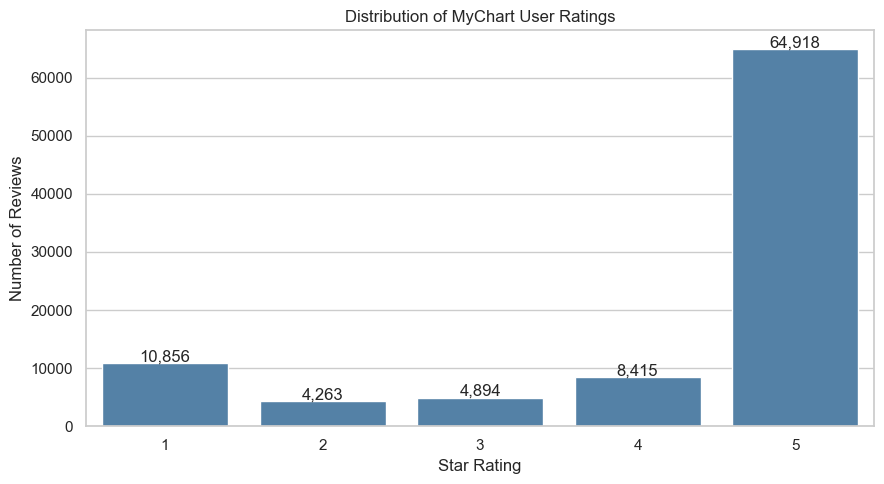

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

rating_counts = (
    mychart_clean["score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .sort_index()
)

rating_percentages = (
    rating_counts / rating_counts.sum() * 100
).round(2)

rating_summary = pd.DataFrame({
    "Review Count": rating_counts,
    "Percentage": rating_percentages
})

display(rating_summary)

print("Average rating:", round(mychart_clean["score"].mean(), 2))
print("Median rating:", mychart_clean["score"].median())

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color="steelblue"
)

for i, count in enumerate(rating_counts.values):
    ax.text(i, count + 300, f"{count:,}", ha="center")

plt.title("Distribution of MyChart User Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

,review_length_words,review_length_chars
count,93346.000000,93346.000000
mean,18.750820,100.762154
std,19.762481,106.496072
min,1.000000,1.000000
25%,5.000000,27.000000
50%,12.000000,66.000000
75%,25.000000,134.000000
max,675.000000,3699.000000


Average review length (words): 18.75
Median review length (words): 12.0


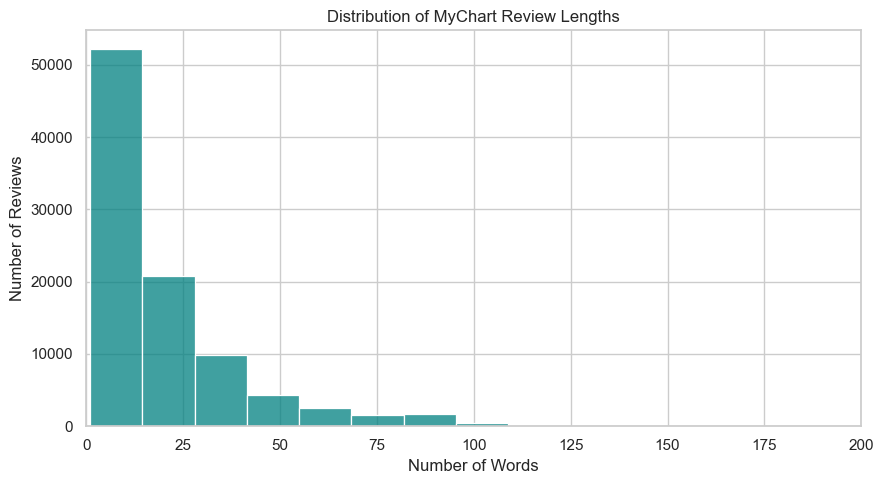

In [6]:
length_summary = mychart_clean[
    ["review_length_words", "review_length_chars"]
].describe()

display(length_summary)

print(
    "Average review length (words):",
    round(mychart_clean["review_length_words"].mean(), 2)
)

print(
    "Median review length (words):",
    mychart_clean["review_length_words"].median()
)

plt.figure(figsize=(9, 5))

sns.histplot(
    mychart_clean["review_length_words"],
    bins=50,
    color="teal"
)

plt.title("Distribution of MyChart Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.xlim(0, 200)
plt.tight_layout()
plt.show()

,count,mean,median
score,,,
1,10856,25.73,18.0
2,4263,29.70,23.0
3,4894,28.39,21.0
4,8415,22.11,15.0
5,64918,15.70,10.0


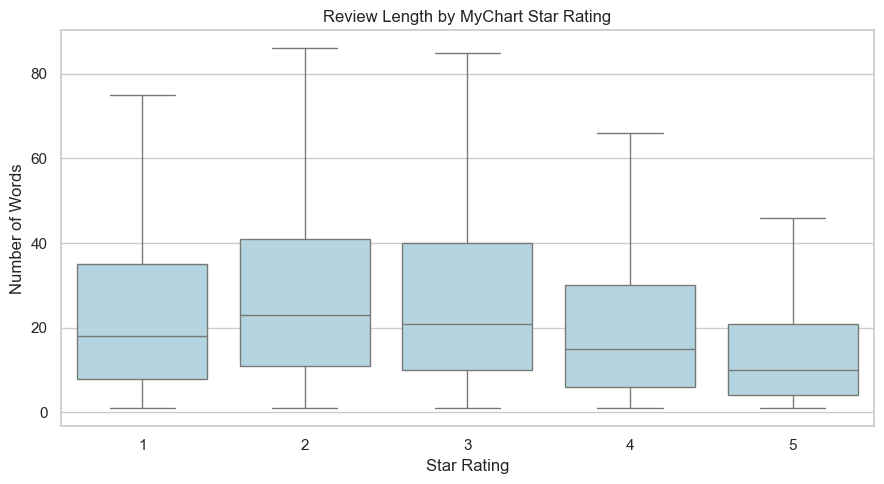

In [7]:
length_by_rating = (
    mychart_clean
    .groupby("score")["review_length_words"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(length_by_rating)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=mychart_clean,
    x="score",
    y="review_length_words",
    color="lightblue",
    showfliers=False
)

plt.title("Review Length by MyChart Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()


### 3.1 Interpretation of Exploratory Findings

**Rating distribution:** Among the 93,346 cleaned MyChart reviews, 69.55% received five stars, while 11.63% received one star. The average rating was 4.20 and the median rating was 5. This indicates that highly positive ratings dominate the collected reviews, although a substantial set of lower-rated experiences remains available for analysis.

**Review length:** Reviews contained an average of 18.75 words and a median of 12 words. The difference between the mean and median, together with a maximum of 675 words, suggests a right-skewed distribution in which most reviews are relatively short but some are much longer.

**Rating and review length:** Two-star reviews averaged 29.70 words, compared with 15.70 words for five-star reviews. One-star reviews averaged 25.73 words. This suggests that lower-rated reviewers often provide more written detail, potentially offering richer material for extracting user-reported problems.

**Business implications:** Product managers and digital healthcare stakeholders should not rely exclusively on aggregate star ratings. Examining the content of lower-rated reviews may reveal actionable concerns that are obscured by the overall positive rating distribution. Subsequent text-mining analyses will investigate recurring terms, sentiment, and reported issues across review categories.

**Limitations:** These findings describe the collected review dataset rather than all MyChart users. Review authors are self-selected, and star ratings do not necessarily correspond to specific technical or healthcare-access problems. Descriptive associations between rating and review length should not be interpreted as causal relationships.



## 4. Text Preprocessing and Keyword Analysis

This section prepares MyChart review text for exploratory natural language processing.

The objectives are to:
- Normalize review text and remove common stopwords.
- Identify frequently occurring words (unigrams).
- Identify commonly occurring two-word combinations (bigrams).
- Explore vocabulary that may help identify user-reported experiences and concerns.

The preprocessing preserves the original review text for later sentiment analysis and interpretation. Frequent terms are descriptive signals, not automatically validated issue categories.


In [8]:

import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Preserve original review text for later analysis
mychart_clean["original_text"] = mychart_clean["content"].copy()

# Keep negation terms because they may carry important meaning
custom_stopwords = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "nor", "never"
}

def preprocess_review(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    tokens = re.findall(r"[a-z]+(?:'[a-z]+)?", text)
    tokens = [
        token for token in tokens
        if token not in custom_stopwords and len(token) > 1
    ]
    return " ".join(tokens)

mychart_clean["processed_text"] = (
    mychart_clean["original_text"].apply(preprocess_review)
)

print("Reviews processed:", len(mychart_clean))
print("Empty processed reviews:",
      mychart_clean["processed_text"].eq("").sum())

display(
    mychart_clean[
        ["original_text", "processed_text"]
    ].head(10)
)


Reviews processed: 93346
Empty processed reviews: 306


,original_text,processed_text
480,very easy to use and follow up with my care,easy use follow care
481,"Best information, since the wheel.",best information wheel
482,i found everything i was looking for plus some...,looking plus thank chart
483,MyChart is an incredibly convenient app for ma...,mychart incredibly convenient app managing hea...
484,"it's very helpful, all involved are able to ac...",it's helpful involved able access information ...
485,"Since the update, I cannot send messages to th...",update send messages providers son's pcp video...
486,Great app,great app
487,it's a great way for me to talk to my doctors ...,it's great way talk doctors appointment change...
488,It would be very helpful if I could find the a...,helpful app phone umc medical center instead m...
489,thanks for it I love it,thanks love


,Term,Frequency
39,app,36030
240,easy,17660
486,love,16906
338,great,14169
931,use,14038
741,results,12500
43,appointments,11422
556,not,10322
421,it,9340
507,medical,8949


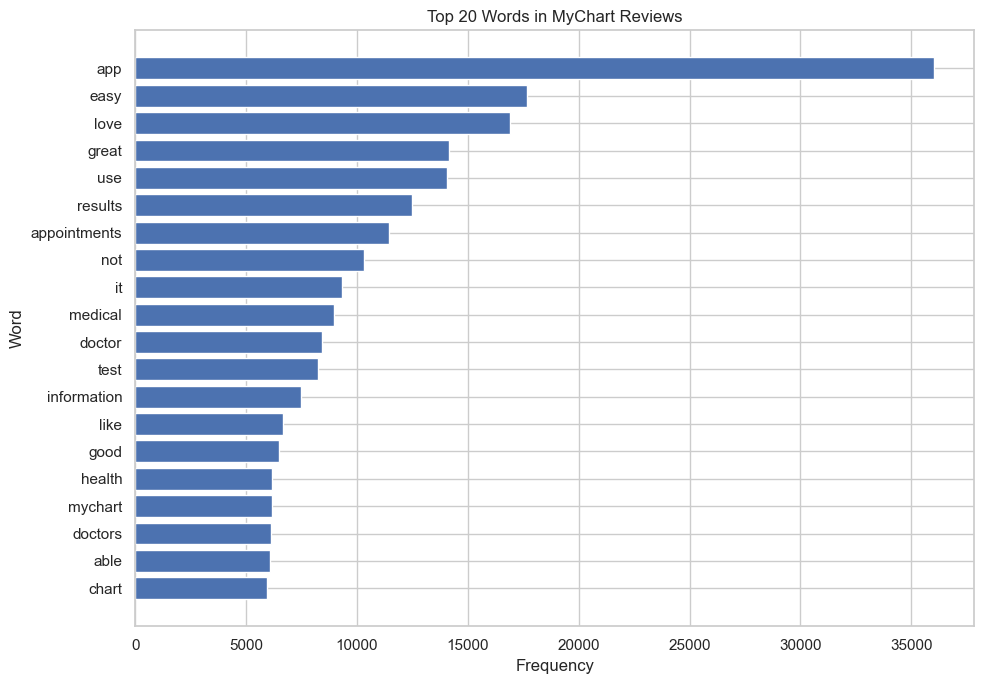

In [9]:

from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import pandas as pd

texts = mychart_clean.loc[
    mychart_clean["processed_text"].ne(""),
    "processed_text"
]

unigram_vectorizer = CountVectorizer(
    ngram_range=(1, 1),
    max_features=1000
)

unigram_matrix = unigram_vectorizer.fit_transform(texts)

unigram_counts = unigram_matrix.sum(axis=0).A1

unigram_df = pd.DataFrame({
    "Term": unigram_vectorizer.get_feature_names_out(),
    "Frequency": unigram_counts
}).sort_values("Frequency", ascending=False)

display(unigram_df.head(20))

top_unigrams = unigram_df.head(20).sort_values("Frequency")

plt.figure(figsize=(10, 7))
plt.barh(top_unigrams["Term"], top_unigrams["Frequency"])
plt.title("Top 20 Words in MyChart Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()


,Bigram,Frequency
340,easy use,8096
872,test results,7066
566,love app,4484
394,great app,3852
944,user friendly,1615
332,easy navigate,1547
61,app easy,1487
620,medical records,1387
435,health care,1259
613,medical information,1218


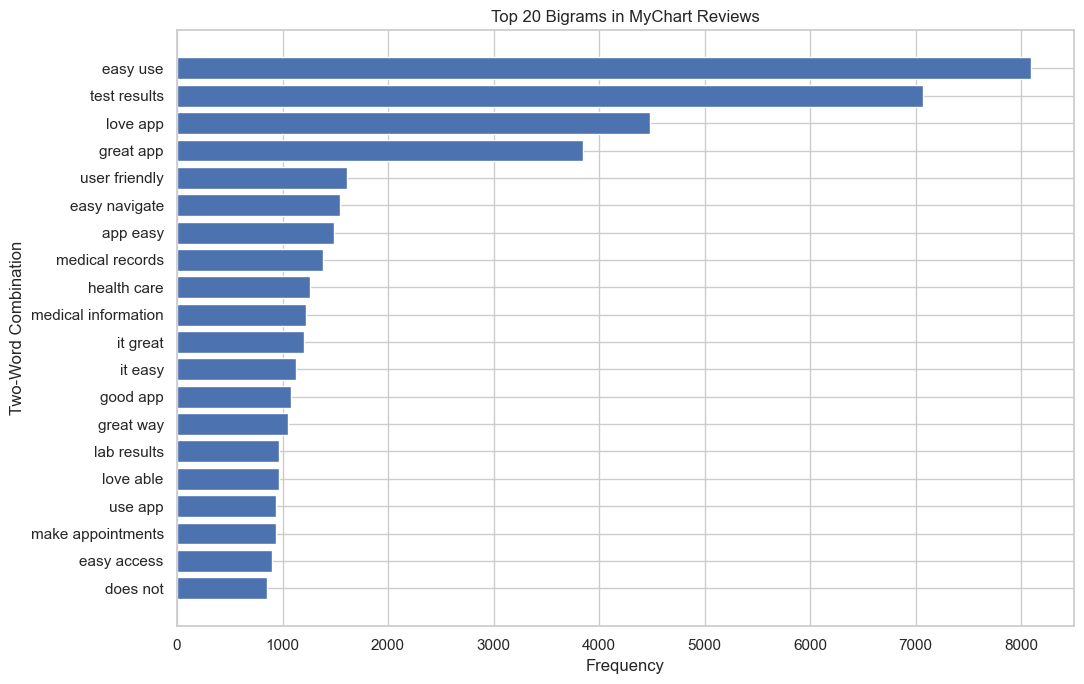

In [10]:

bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    max_features=1000
)

bigram_matrix = bigram_vectorizer.fit_transform(texts)

bigram_counts = bigram_matrix.sum(axis=0).A1

bigram_df = pd.DataFrame({
    "Bigram": bigram_vectorizer.get_feature_names_out(),
    "Frequency": bigram_counts
}).sort_values("Frequency", ascending=False)

display(bigram_df.head(20))

top_bigrams = bigram_df.head(20).sort_values("Frequency")

plt.figure(figsize=(11, 7))
plt.barh(top_bigrams["Bigram"], top_bigrams["Frequency"])
plt.title("Top 20 Bigrams in MyChart Reviews")
plt.xlabel("Frequency")
plt.ylabel("Two-Word Combination")
plt.tight_layout()
plt.show()


In [11]:
pip install vaderSentiment

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



## 5. Sentiment Analysis Using VADER

This section applies VADER, a lexicon-based sentiment analysis method, to the original MyChart review text.

The objectives are to:
- Classify reviews into positive, neutral, and negative sentiment.
- Compare sentiment classifications with user star ratings.
- Identify disagreements between text sentiment and numerical ratings.
- Assess the usefulness and limitations of sentiment analysis for understanding patient-reported experiences.

VADER provides an interpretable baseline rather than a validated measure of patient trust or healthcare application quality.


In [12]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

# Apply VADER to the original text, not the stopword-removed text
mychart_clean["vader_compound"] = (
    mychart_clean["original_text"]
    .apply(lambda text: analyzer.polarity_scores(str(text))["compound"])
)

def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    return "Neutral"

mychart_clean["vader_sentiment"] = (
    mychart_clean["vader_compound"].apply(classify_sentiment)
)

sentiment_summary = (
    mychart_clean["vader_sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
    .rename_axis("Sentiment")
    .reset_index(name="Review Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Review Count"]
    / len(mychart_clean) * 100
).round(2)

display(sentiment_summary)


,Sentiment,Review Count,Percentage
0,Positive,70465,75.49
1,Neutral,11588,12.41
2,Negative,11293,12.10


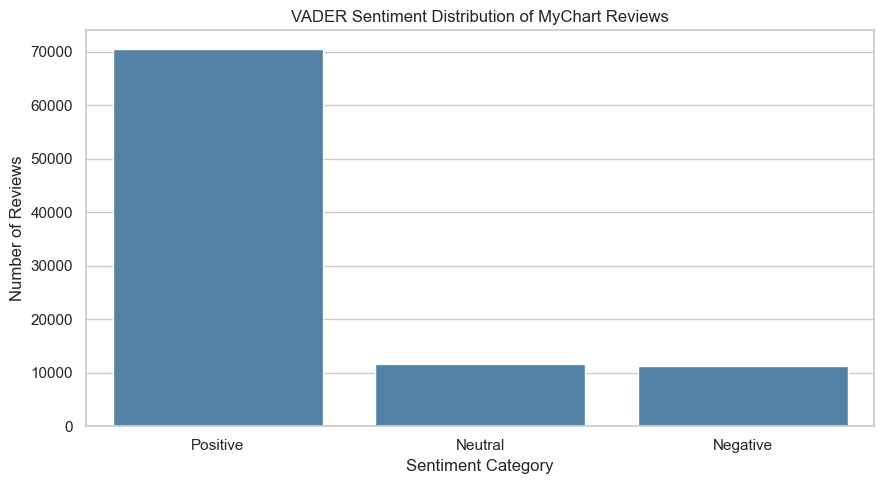

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=sentiment_summary,
    x="Sentiment",
    y="Review Count",
    order=["Positive", "Neutral", "Negative"],
    color="steelblue"
)

plt.title("VADER Sentiment Distribution of MyChart Reviews")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


vader_sentiment,Positive,Neutral,Negative
score,,,
1,2182,3059,5615
2,1263,985,2015
3,2062,1117,1715
4,6483,1059,873
5,58475,5368,1075


vader_sentiment,Positive,Neutral,Negative
score,,,
1,20.10,28.18,51.72
2,29.63,23.11,47.27
3,42.13,22.82,35.04
4,77.04,12.58,10.37
5,90.08,8.27,1.66


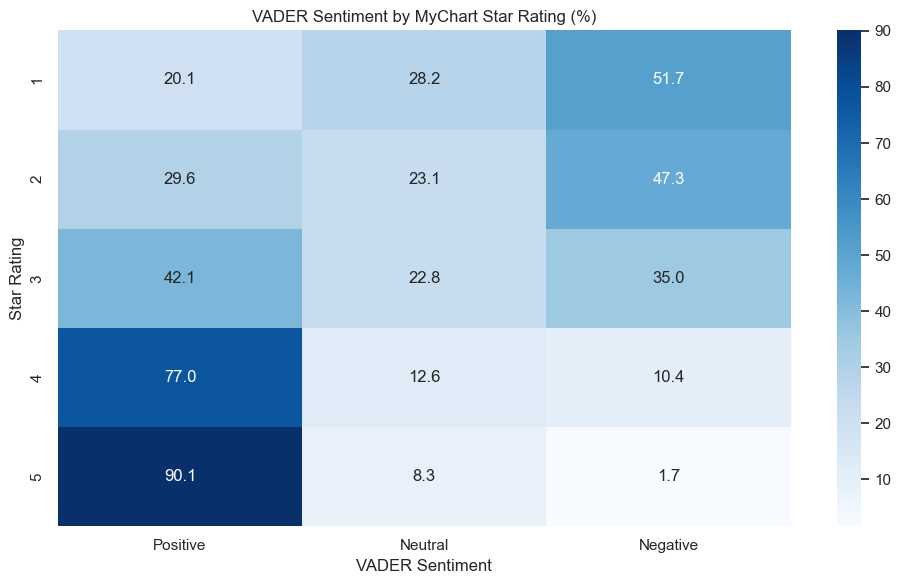

In [14]:

rating_sentiment_counts = pd.crosstab(
    mychart_clean["score"],
    mychart_clean["vader_sentiment"]
).reindex(
    index=[1, 2, 3, 4, 5],
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

rating_sentiment_pct = (
    rating_sentiment_counts
    .div(rating_sentiment_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(2)
)

display(rating_sentiment_counts)
display(rating_sentiment_pct)

plt.figure(figsize=(10, 6))
sns.heatmap(
    rating_sentiment_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("VADER Sentiment by MyChart Star Rating (%)")
plt.xlabel("VADER Sentiment")
plt.ylabel("Star Rating")
plt.tight_layout()
plt.show()


In [15]:

# Positive text sentiment despite a low star rating
low_rating_positive = mychart_clean[
    (mychart_clean["score"] <= 2) &
    (mychart_clean["vader_sentiment"] == "Positive")
]

# Negative text sentiment despite a high star rating
high_rating_negative = mychart_clean[
    (mychart_clean["score"] >= 4) &
    (mychart_clean["vader_sentiment"] == "Negative")
]

print("Low-rated reviews with positive VADER sentiment:",
      len(low_rating_positive))

print("High-rated reviews with negative VADER sentiment:",
      len(high_rating_negative))

# Avoid printing identifiable review content or IDs in public outputs.
print(
    "Total rating-sentiment disagreements:",
    len(low_rating_positive) + len(high_rating_negative)
)


Low-rated reviews with positive VADER sentiment: 3445
High-rated reviews with negative VADER sentiment: 1948
Total rating-sentiment disagreements: 5393



### 5.1 Rating–Sentiment Disagreement Analysis

The VADER sentiment analysis identified 5,393 reviews (approximately 5.78% of the 93,346 cleaned MyChart reviews) where the sentiment classification differed from the general direction of the numerical star rating.

Specifically:
- 3,445 reviews rated one or two stars were classified as positive by VADER.
- 1,948 reviews rated four or five stars were classified as negative by VADER.

These disagreements suggest that numerical ratings and automated text sentiment do not always convey the same information.

**Business implications:** Relying exclusively on star ratings or automated sentiment could overlook important aspects of patient-reported experiences. Reviews with conflicting signals may warrant closer qualitative examination, especially when identifying technical difficulties, usability concerns, and access-related problems.

**Limitations:** These cases are flagged disagreements rather than verified classification errors. VADER is a general-purpose sentiment tool and may struggle with mixed opinions, negation, sarcasm, and healthcare-specific terminology. The disagreement counts do not establish the prevalence of actual MyChart problems.



## 6. Preliminary Findings, Limitations, and Next Steps

### Preliminary Findings

The analysis examined 93,346 cleaned MyChart reviews from the HARPT dataset.

1. **Rating distribution:** Five-star ratings accounted for 69.55% of reviews, with an average rating of 4.20 out of 5. However, lower-rated reviews provide an important source of user-reported concerns.

2. **Review length:** Reviews averaged 18.75 words, with a median of 12 words. Lower-rated reviews generally contained more words than five-star reviews, suggesting they may provide more detailed descriptions of user experiences.

3. **Text mining:** Preprocessing and unigram/bigram analysis established an exploratory foundation for examining frequently used language. Frequent terms require contextual interpretation before they can be treated as specific user concerns.

4. **Sentiment disagreements:** VADER identified 5,393 reviews (5.78%) with disagreements between numerical ratings and automated text sentiment. This supports examining review text alongside star ratings rather than relying on either measure alone.

### Limitations

- App-store reviews represent self-selected users and may not reflect the experiences of all MyChart users.
- The dataset covers reviews through April 2025 and does not describe current app performance.
- Repeated review texts may influence term-frequency results.
- VADER is not a healthcare-specific sentiment classifier.
- Automated sentiment disagreements are not verified classification errors.
- Frequent keywords and phrases do not independently establish the existence or prevalence of specific problems.
- The existing trust-related fields in the source dataset have not been independently validated.

### Next Steps

The next stage will use TF-IDF and NMF topic modeling to identify candidate themes within MyChart reviews. Topics will require manual examination and careful labeling before being interpreted as user-reported issue categories.

Subsequent analyses will investigate temporal and app-version patterns where data coverage permits. These comparisons will be descriptive and will not establish causal effects.

Phase III will explore selective LLM-assisted extraction of interpretable user concerns, supported by human validation, cost assessment, and privacy considerations.


## 7. Topic Modeling Using TF-IDF and NMF

This section uses TF-IDF vectorization and Non-Negative Matrix
Factorization (NMF) to discover recurring themes in MyChart reviews.

The objective is to identify candidate themes related to user
experiences, technical reliability, usability, and access to
health information.

Topic labels will be interpreted and manually validated rather
than treated as automatically verified issue categories.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Use the cleaned text created in Section 4
topic_texts = mychart_clean.loc[
    mychart_clean["processed_text"].fillna("").str.strip().ne(""),
    "processed_text"
]

# Create TF-IDF features
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(topic_texts)

print("Reviews used for topic modeling:", tfidf_matrix.shape[0])
print("Number of TF-IDF features:", tfidf_matrix.shape[1])

# Initial six-topic model
nmf_model = NMF(
    n_components=6,
    random_state=42,
    init="nndsvda",
    max_iter=400
)

document_topics = nmf_model.fit_transform(tfidf_matrix)

feature_names = tfidf_vectorizer.get_feature_names_out()

# Display the 12 most influential terms per topic
for topic_idx, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-12:][::-1]
    top_terms = [feature_names[i] for i in top_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_terms))

Reviews used for topic modeling: 93040
Number of TF-IDF features: 5000

Topic 1:
great, great app, app, works great, it great, works, great way, app great, great experience, great easy, great tool, experience

Topic 2:
easy, easy use, use, app easy, convenient, navigate, easy navigate, it easy, convenient easy, use convenient, love easy, use love

Topic 3:
love, love app, love chart, app, love mychart, love easy, absolutely love, chart, love love, absolutely, love able, use love

Topic 4:
good, good app, it good, far, far good, good experience, experience, not good, it, really good, app, pretty good

Topic 5:
app, love app, results, excellent, great app, appointments, test, test results, medical, it, not, like

Topic 6:
helpful, app helpful, helpful app, it helpful, use helpful, helpful easy, convenient, it, extremely helpful, helpful convenient, extremely, informative



### 7.1 Refining Topic Modeling for User-Reported Concerns

The initial NMF model identified predominantly positive and overlapping themes, including general satisfaction, ease of use, and helpfulness.

Because the project focuses on understanding user-reported issues, a second exploratory NMF model is developed using reviews with one-star and two-star ratings.

This targeted analysis aims to identify more specific language associated with technical difficulties, healthcare information access, usability, and other reported concerns.

The low-rating subset is used for theme discovery rather than estimating the prevalence of issues across all MyChart users. Candidate topics will require examination of representative reviews and manual validation.


In [17]:
# Select reviews with 1-star or 2-star ratings
negative_reviews = mychart_clean.loc[
    mychart_clean["score"].isin([1, 2]) &
    mychart_clean["processed_text"].fillna("").str.strip().ne("")
].copy()

print("Low-rated reviews available:", len(negative_reviews))

# Build TF-IDF features for low-rated reviews
negative_tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

negative_tfidf_matrix = (
    negative_tfidf_vectorizer.fit_transform(
        negative_reviews["processed_text"]
    )
)

# Train NMF model on low-rated reviews
negative_nmf_model = NMF(
    n_components=6,
    random_state=42,
    init="nndsvda",
    max_iter=400
)

negative_document_topics = (
    negative_nmf_model.fit_transform(negative_tfidf_matrix)
)

negative_feature_names = (
    negative_tfidf_vectorizer.get_feature_names_out()
)

# Display top terms for each topic
for topic_idx, topic in enumerate(negative_nmf_model.components_):

    top_indices = topic.argsort()[-15:][::-1]

    top_terms = [
        negative_feature_names[i]
        for i in top_indices
    ]

    print(f"\nConcern-focused Topic {topic_idx + 1}:")
    print(", ".join(top_terms))

Low-rated reviews available: 15094

Concern-focused Topic 1:
app, no, use, results, time, it, don, just, test, never, message, information, test results, messages, like

Concern-focused Topic 2:
not, does, does not, not work, friendly, user, user friendly, not user, not working, work, working, not good, good, app not, app does

Concern-focused Topic 3:
work, doesn, doesn work, not work, app doesn, don work, does, does not, work time, time, password, phone, half, didn work, don

Concern-focused Topic 4:
can, can log, can access, can login, can sign, access, account, chart, can open, sign, log, login, open, can chart, can app

Concern-focused Topic 5:
log, let, won, won let, let log, password, can log, sign, not let, let sign, try, keeps, wont, app won, says

Concern-focused Topic 6:
sucks, app sucks, app, sucks can, better, really sucks, sucks not, health, sucks never, horrible, totally sucks, password, far, absolutely, sucks no



### 7.2 Topic Interpretation and Representative Review Validation

To interpret the concern-focused NMF model, representative reviews are examined for each topic.

Reviews are ranked by their NMF topic weights, and a small sample of highly associated reviews is inspected to determine whether the topic terms correspond to coherent user-reported concerns.

This qualitative examination supports provisional topic labeling and helps identify overlapping or sentiment-dominated topics.

The review samples are illustrative rather than statistically representative. Final issue labels require additional manual validation.


In [18]:
import numpy as np
import pandas as pd

# Assign each review its highest-weighted NMF topic
negative_reviews["dominant_topic"] = (
    negative_document_topics.argmax(axis=1) + 1
)

negative_reviews["topic_weight"] = (
    negative_document_topics.max(axis=1)
)

# Count reviews assigned to each topic
topic_counts = (
    negative_reviews["dominant_topic"]
    .value_counts()
    .sort_index()
)

topic_distribution = pd.DataFrame({
    "Topic": topic_counts.index,
    "Review Count": topic_counts.values,
    "Percentage": (
        topic_counts.values / len(negative_reviews) * 100
    ).round(2)
})

display(topic_distribution)

# Inspect five highly associated reviews per topic
# Review IDs are intentionally excluded.
for topic_number in range(1, 7):

    print(f"\n{'=' * 55}")
    print(f"TOPIC {topic_number} — REPRESENTATIVE REVIEWS")
    print(f"{'=' * 55}")

    topic_sample = (
        negative_reviews[
            negative_reviews["dominant_topic"] == topic_number
        ]
        .sort_values("topic_weight", ascending=False)
        .head(5)
    )

    for review_number, review in enumerate(
        topic_sample["original_text"], start=1
    ):
        print(f"\nReview {review_number}:")
        print(str(review)[:500])

,Topic,Review Count,Percentage
0,1,7991,52.94
1,2,2507,16.61
2,3,857,5.68
3,4,1687,11.18
4,5,1705,11.30
5,6,347,2.30



TOPIC 1 — REPRESENTATIVE REVIEWS

Review 1:
I cant even get on this dang app

Review 2:
Cant get app to ope

Review 3:
What a do nothing app!

Review 4:
This is a very frustating app

Review 5:
This app is taped together with duct tape

TOPIC 2 — REPRESENTATIVE REVIEWS

Review 1:
Not thrilled

Review 2:
Not trabaja pnma

Review 3:
Rather not.

Review 4:
Would not reccommend

Review 5:
Not all thst to.me

TOPIC 3 — REPRESENTATIVE REVIEWS

Review 1:
Doesn't work well

Review 2:
Doesn't work

Review 3:
Doesn't work

Review 4:
Doesn't work

Review 5:
It doesn't work,

TOPIC 4 — REPRESENTATIVE REVIEWS

Review 1:
Can't get on to my carle

Review 2:
You can't do anything

Review 3:
I can't get into it

Review 4:
Can't find it

Review 5:
can't sighn in

TOPIC 5 — REPRESENTATIVE REVIEWS

Review 1:
Won't let me log inv

Review 2:
Won't let me log in at all

Review 3:
It won't let me log in

Review 4:
Won't let me log in

Review 5:
Won't let me log in.

TOPIC 6 — REPRESENTATIVE REVIEWS

Review 1


### 7.3 Qualitative Validation Using Informative Reviews

Initial inspection of the highest-weighted reviews revealed that many were extremely short and contained general expressions of dissatisfaction rather than descriptions of specific problems.

To improve interpretability, an additional qualitative examination focuses on reviews containing at least 15 words.

This approach helps identify more detailed examples of user-reported experiences while retaining the original NMF topic assignments.

The longer-review subset is used only for interpretation and does not replace the full topic-modeling dataset. Its findings may be biased toward users who provide more detailed feedback.


In [19]:
# Select more informative reviews for qualitative examination
informative_reviews = negative_reviews.loc[
    negative_reviews["review_length_words"] >= 15
].copy()

print("Low-rated reviews:", len(negative_reviews))
print("Reviews with at least 15 words:", len(informative_reviews))

# Inspect 5 longer reviews per topic
for topic_number in range(1, 7):

    print(f"\n{'=' * 60}")
    print(f"TOPIC {topic_number} — INFORMATIVE REVIEWS")
    print(f"{'=' * 60}")

    topic_sample = (
        informative_reviews.loc[
            informative_reviews["dominant_topic"] == topic_number
        ]
        .sort_values("topic_weight", ascending=False)
        .head(5)
    )

    for review_number, review in enumerate(
        topic_sample["original_text"], start=1
    ):
        print(f"\nReview {review_number}:")
        print(str(review)[:600])

Low-rated reviews: 15094
Reviews with at least 15 words: 9103

TOPIC 1 — INFORMATIVE REVIEWS

Review 1:
You'll die using this app! The one GIANT problem is that every health care provider uses a different system or none at all. My Chart has a way to link to a few, mine wasn't listed. I refuse to sign up for all these because I'd have 50+ health provider apps by now! I had some and the doctor's office didn't seem to use it either! This is a nightmare for the patient, let alone an elderly patient. Either get together and figure out one app that everyone uses or just forget it. It is just a much more complicated way of trying to connect with your ONE doctor. Then you get to repeat this for each hea

Review 2:
CANNOT USE APP! Click on app, told I'm using an old app! I have to update! NO WAY TO UPDATE!!!! Trying for DAYS! I've been in excruciating pain all weekend long! (Easter weekend)No one in doctor's office! ONLY WAY to contact doctor, is through the app! Jumping through hoops all day! 


### 7.4 Preliminary Topic Modeling Findings

The initial NMF model trained on 93,040 processed MyChart reviews primarily identified positive expressions such as "great," "easy," "love," and "helpful."

To better investigate user-reported concerns, a second six-topic NMF model was trained on 15,094 low-rated reviews.

The concern-focused model revealed recurring language associated with application functionality, login difficulties, account access, and general dissatisfaction.

The dominant-topic assignments were distributed as follows:

- Topic 1: 52.94%
- Topic 2: 16.61%
- Topic 3: 5.68%
- Topic 4: 11.18%
- Topic 5: 11.30%
- Topic 6: 2.30%

Inspection of representative reviews suggested that Topic 5 was relatively coherent around login difficulties, while several other topics overlapped or reflected general dissatisfaction.

These results demonstrate a limitation of unsupervised topic modeling: mathematically distinct topics do not necessarily correspond to distinct, actionable user problems.

The topic percentages represent assignments within the low-rated review subset, not verified issue prevalence among all MyChart users.

Further qualitative examination is necessary before establishing final issue labels.



### 7.5 Findings from Qualitative Review Inspection

Of the 15,094 low-rated reviews included in the concern-focused topic model, 9,103 contained at least 15 words, representing approximately 60.3% of the subset.

The longer-review examination provided more contextual information than the initial highest-weighted examples, many of which consisted of short expressions of dissatisfaction.

Detailed examples from Topic 1 described several potential user concerns, including:

- Difficulties connecting healthcare providers and systems
- Application updates and device compatibility
- Login failures, unexpected logouts, and error messages
- Missing medical records and test results
- Challenges with provider messaging and appointment scheduling

These findings suggest that individual NMF topics can contain multiple distinct concerns. Consequently, the topic assignments should not be interpreted as validated issue categories or used directly to estimate issue prevalence.

The analysis supports further development of a manually reviewed issue taxonomy, with categories grounded in the content of reviews rather than topic numbers alone.



## 8. Temporal and App-Version Analysis

This section examines how MyChart review activity and low-rating patterns vary over time and across recorded app versions.

The objectives are to:
- Examine annual review volumes and average star ratings.
- Compare the proportion of low-rated reviews across years.
- Assess the availability and coverage of app-version information.
- Explore differences across versions where sufficient data is available.

These analyses are descriptive. Changes in review patterns cannot establish that a particular app update caused a change in user experience.


In [20]:

# Prepare temporal variables
mychart_clean["review_year"] = mychart_clean["at"].dt.year

mychart_clean["is_low_rating"] = (
    mychart_clean["score"].isin([1, 2])
)

# Calculate yearly statistics
yearly_summary = (
    mychart_clean
    .groupby("review_year")
    .agg(
        total_reviews=("score", "size"),
        average_rating=("score", "mean"),
        low_rated_reviews=("is_low_rating", "sum"),
        low_rating_share=("is_low_rating", "mean")
    )
    .reset_index()
)

yearly_summary["average_rating"] = (
    yearly_summary["average_rating"].round(2)
)

yearly_summary["low_rating_share_pct"] = (
    yearly_summary["low_rating_share"] * 100
).round(2)

display(
    yearly_summary[
        [
            "review_year",
            "total_reviews",
            "average_rating",
            "low_rated_reviews",
            "low_rating_share_pct"
        ]
    ]
)


,review_year,total_reviews,average_rating,low_rated_reviews,low_rating_share_pct
0,2011,19,4.11,3,15.79
1,2012,215,3.06,94,43.72
2,2013,278,3.43,88,31.65
3,2014,852,3.92,184,21.60
4,2015,933,3.43,298,31.94
5,2016,1000,3.66,279,27.90
6,2017,866,3.60,242,27.94
7,2018,1094,3.46,366,33.46
8,2019,2450,3.73,662,27.02
9,2020,5212,3.52,1736,33.31


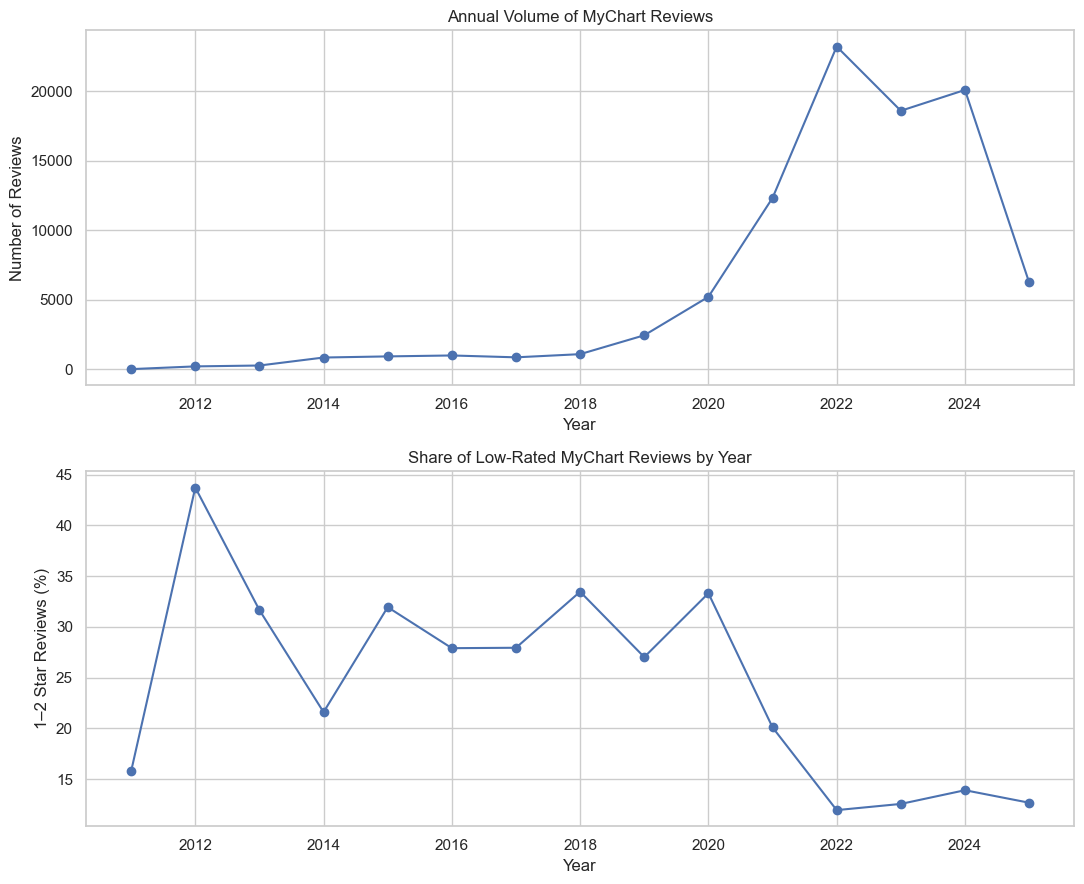

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(11, 9))

axes[0].plot(
    yearly_summary["review_year"],
    yearly_summary["total_reviews"],
    marker="o"
)
axes[0].set_title("Annual Volume of MyChart Reviews")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Number of Reviews")

axes[1].plot(
    yearly_summary["review_year"],
    yearly_summary["low_rating_share_pct"],
    marker="o"
)
axes[1].set_title("Share of Low-Rated MyChart Reviews by Year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("1–2 Star Reviews (%)")

plt.tight_layout()
plt.show()


In [22]:

# Normalize version values
mychart_clean["app_version"] = (
    mychart_clean["reviewCreatedVersion"]
    .astype("string")
    .str.strip()
)

mychart_clean["app_version"] = (
    mychart_clean["app_version"]
    .replace("", pd.NA)
)

version_coverage = (
    mychart_clean["app_version"].notna().mean() * 100
)

print(
    "Reviews with recorded app versions:",
    round(version_coverage, 2),
    "%"
)

print(
    "Distinct recorded versions:",
    mychart_clean["app_version"].nunique()
)

# Show the 15 most frequently recorded versions
top_versions = (
    mychart_clean["app_version"]
    .value_counts()
    .head(15)
)

display(top_versions)


Reviews with recorded app versions: 91.38 %
Distinct recorded versions: 128


app_version
9.9.2     3596
10.2.1    3303
10.2.4    3025
9.9.1     2612
9.9.4     2465
10.6.3    2012
11.1.5    1965
11.2.4    1952
10.5.3    1943
10.4.1    1906
10.8.5    1850
10.1.5    1839
10.2.3    1819
10.9.2    1774
10.4.2    1761
Name: count, dtype: int64[pyarrow]


### 8.1 Interpretation of Annual Review Trends

The temporal analysis identified substantial variation in MyChart review activity and rating distributions between 2011 and 2025.

Review volume increased considerably in later years, reaching its highest observed annual count in 2022 with 23,195 reviews.

The proportion of low-rated reviews declined from 33.31% in 2020 to 11.95% in 2022, while average ratings increased from 3.52 to 4.37.

During 2023 and 2024, average ratings remained above 4.30, with low-rating shares of 12.56% and 13.91%, respectively.

These patterns describe changes in the observed review dataset rather than verified improvements in application quality.

The 2025 data covers only part of the calendar year, and the earliest years contain relatively few reviews. Consequently, annual comparisons should be interpreted with attention to differences in sample size and temporal coverage.



### 8.2 App-Version Comparison

Recorded MyChart app versions are compared using review counts, average star ratings, and the proportion of one-star and two-star reviews.

Versions with fewer than 500 reviews are excluded from the primary comparison to avoid emphasizing unstable percentages based on small samples.

Version-level differences are descriptive associations. They cannot establish whether particular software releases caused reported user difficulties.

App-version values may also be associated with different review periods, making temporal confounding an important limitation.


In [24]:
# Summarize reviews by recorded app version
version_summary = (
    mychart_clean.dropna(subset=["app_version"])
    .groupby("app_version")
    .agg(
        total_reviews=("score", "size"),
        average_rating=("score", "mean"),
        low_rated_reviews=("is_low_rating", "sum"),
        low_rating_share=("is_low_rating", "mean")
    )
    .reset_index()
)

version_summary["average_rating"] = (
    version_summary["average_rating"].round(2)
)

version_summary["low_rating_share_pct"] = (
    version_summary["low_rating_share"] * 100
).round(2)

# Retain versions with at least 500 reviews
version_comparison = (
    version_summary.loc[
        version_summary["total_reviews"] >= 500
    ]
    .sort_values(
        "low_rating_share_pct",
        ascending=False
    )
)

print(
    "Versions with at least 500 reviews:",
    len(version_comparison)
)

display(
    version_comparison[
        [
            "app_version",
            "total_reviews",
            "average_rating",
            "low_rated_reviews",
            "low_rating_share_pct"
        ]
    ].head(15)
)

Versions with at least 500 reviews: 49


,app_version,total_reviews,average_rating,low_rated_reviews,low_rating_share_pct
118,9.7.2,605,3.48,200,33.06
111,9.5.5,633,3.56,206,32.54
115,9.6.3,548,3.53,178,32.48
90,9.1.2,517,3.77,137,26.50
42,11.2.2,838,3.99,184,21.96
86,8.8,588,3.92,129,21.94
123,9.8.4,1196,4.08,230,19.23
122,9.8.3,1242,4.15,211,16.99
29,10.8.2,844,4.26,131,15.52
14,10.3.1,942,4.29,138,14.65


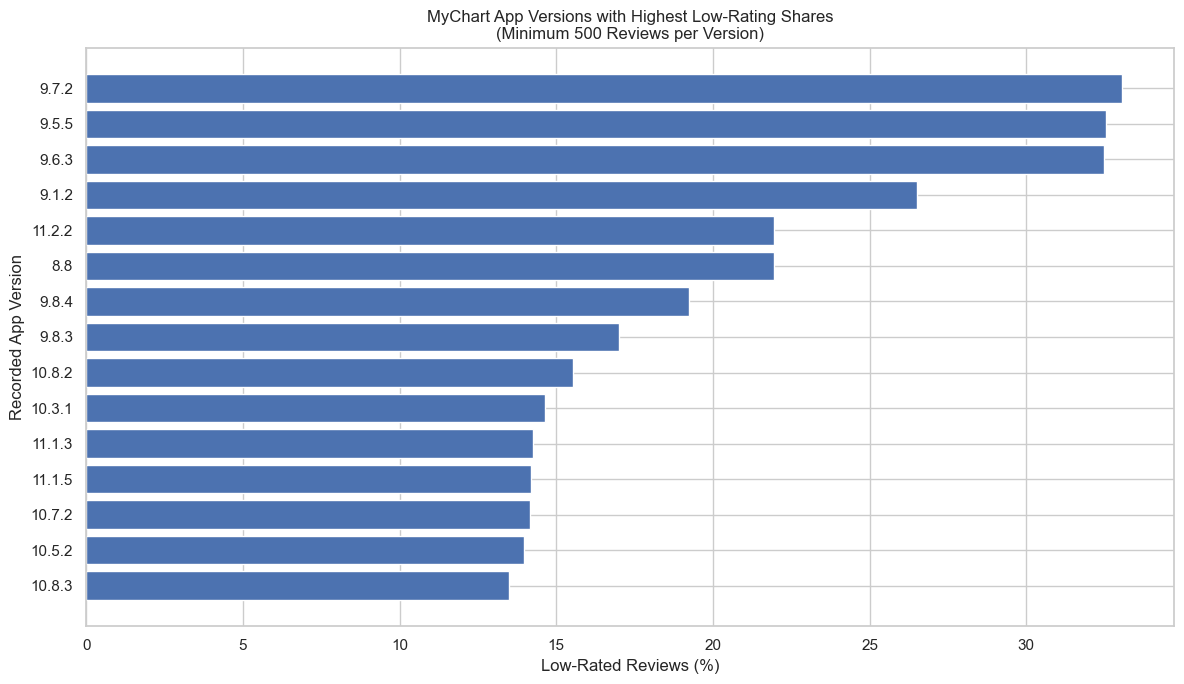

In [25]:
# Visualize the 15 versions with the highest low-rating share
top_low_rating_versions = version_comparison.head(15)

plt.figure(figsize=(12, 7))

plt.barh(
    top_low_rating_versions["app_version"].astype(str),
    top_low_rating_versions["low_rating_share_pct"]
)

plt.xlabel("Low-Rated Reviews (%)")
plt.ylabel("Recorded App Version")
plt.title(
    "MyChart App Versions with Highest Low-Rating Shares\n"
    "(Minimum 500 Reviews per Version)"
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### 8.3 Interpretation of App-Version Patterns

App-version information was available for 91.38% of cleaned MyChart reviews, covering 128 distinct recorded versions.

For descriptive comparisons, 49 versions with at least 500 reviews were retained.

Among these versions, 9.7.2 had the highest observed proportion of one-star and two-star reviews (33.06%, 200 of 605 reviews), followed by versions 9.5.5 (32.54%) and 9.6.3 (32.48%).

Version 11.2.2 also exhibited a relatively elevated low-rating share of 21.96%, based on 838 reviews.

These differences identify version-associated patterns worth further investigation, but they do not establish that specific software releases caused the reported difficulties.

Important limitations include:

- App versions may correspond to different calendar periods.
- Reviewers are self-selected and may not represent all app users.
- Some reviews do not contain app-version information.
- Star ratings do not identify the precise reason for dissatisfaction.
- Differences in review composition may contribute to apparent version-level patterns.

Therefore, version comparisons are treated as descriptive signals rather than evidence of software defects or causal relationships.


In [26]:
# Examine review date coverage for selected versions
versions_to_check = [
    "9.7.2", "9.5.5", "9.6.3",
    "11.2.2", "11.1.5"
]

version_date_summary = (
    mychart_clean.loc[
        mychart_clean["app_version"].isin(versions_to_check)
    ]
    .groupby("app_version")
    .agg(
        total_reviews=("score", "size"),
        earliest_review=("at", "min"),
        latest_review=("at", "max"),
        median_review_date=("at", "median")
    )
    .reset_index()
)

display(version_date_summary)

,app_version,total_reviews,earliest_review,latest_review,median_review_date
0,11.1.5,1965,2024-10-14 16:16:00,2025-04-09 09:34:00,2024-11-07 20:31:00
1,11.2.2,838,2024-11-26 12:03:00,2025-04-07 11:57:00,2024-12-07 14:03:00
2,9.5.5,633,2020-12-21 17:20:00,2024-12-19 01:44:00,2021-01-18 21:59:00
3,9.6.3,548,2021-03-15 11:59:00,2025-03-10 02:30:00,2021-04-02 11:07:30
4,9.7.2,605,2021-06-15 14:49:00,2025-03-19 09:03:00,2021-07-14 06:04:00



### 8.4 Date Coverage and Final Interpretation

An additional date-coverage assessment was conducted for selected MyChart app versions to examine whether version-level rating differences might reflect different review periods.

Versions 9.5.5, 9.6.3, and 9.7.2 had median review dates in January, April, and July 2021, respectively. Their low-rating shares were approximately 32–33%.

In contrast, versions 11.1.5 and 11.2.2 had median review dates in November and December 2024, with low-rating shares of 14.20% and 21.96%, respectively.

These findings suggest that calendar period is an important potential confounding factor in app-version comparisons.

Some older recorded versions also appeared in reviews submitted several years later, indicating that recorded version information does not necessarily correspond to a single release period.

Overall, the temporal and version analyses identify descriptive differences in review activity and user ratings. They do not establish that individual app releases caused changes in application quality or user experience.

Future analyses could compare versions within narrower calendar periods and examine manually validated issue categories to better understand these associations.
